# 02 · Approach 1: Heuristics (Rule-Based NLP)

In Chapter 1 the book describes **heuristics-based NLP** as the earliest way of building NLP systems: a human writes down rules that capture their knowledge of the language. Typical tools are:
- **dictionaries and lexicons**: lists of words with a known meaning, e.g. sentiment word lists;
- **knowledge bases** like WordNet;
- **regular expressions** and grammars.

In this notebook we build **two** rule-based sentiment classifiers:
1. **Our own lexicon**: two small word lists, plus rules for *negation* and *contrast*.
2. **VADER**: a well-known rule-based sentiment tool with about 7,500 hand-rated words, available through NLTK.

Neither approach uses the training labels to learn anything. **They need zero labelled examples.** That is their biggest strength.

In [1]:
# --- Make the project's `src` folder importable -----------------------------
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import (
    load_imdb,              # loads train / validation / test DataFrames
    simple_tokenize,        # splits a text into lowercase words
    evaluate,               # computes accuracy, precision, recall, F1
    print_report,           # prints those metrics nicely
    save_results,           # writes results/<name>.json for notebook 05
    save_predictions,       # writes results/predictions/<name>.csv
    Timer,                  # measures run time
)

data = load_imdb()
train, val, test = data["train"], data["validation"], data["test"]
print(f"validation: {len(val):,} reviews | test: {len(test):,} reviews")

validation: 2,500 reviews | test: 5,000 reviews


## Part A: Our own lexicon-based classifier

### A.1 The word lists
We write two small lists by hand, the way an engineer without any data would start: words that typically express a positive or negative opinion about a film.

In [3]:
# Words that usually express a POSITIVE opinion (written by hand, no data used)
POSITIVE_WORDS = {
    "good", "great", "excellent", "amazing", "wonderful", "brilliant", "best",
    "beautiful", "beautifully", "fun", "funny", "enjoyable", "entertaining",
    "charming", "delightful", "moving", "powerful", "touching", "smart",
    "clever", "fresh", "original", "fascinating", "compelling", "engaging",
    "impressive", "remarkable", "superb", "solid", "strong", "love", "loved",
    "lovely", "masterpiece", "perfect", "rich", "witty", "intelligent",
    "thoughtful", "gorgeous", "satisfying", "heartfelt", "memorable",
}

# Words that usually express a NEGATIVE opinion
NEGATIVE_WORDS = {
    "bad", "worst", "awful", "terrible", "horrible", "boring", "bored", "dull",
    "stupid", "dumb", "mess", "messy", "waste", "poor", "poorly", "weak",
    "lame", "tedious", "tiresome", "predictable", "pointless", "silly",
    "annoying", "unfunny", "mediocre", "flat", "lifeless", "bland",
    "disappointing", "disappointment", "fails", "failed", "failure", "worse",
    "ugly", "ridiculous", "forgettable", "clumsy", "incoherent", "hate",
    "pretentious", "shallow", "flawed",
}

# Words that NEGATE (flip) the meaning of the words that follow them
NEGATORS = {"not", "no", "never", "nothing", "neither", "nor", "without", "hardly", "n't"}

print(f"{len(POSITIVE_WORDS)} positive words, {len(NEGATIVE_WORDS)} negative words")

43 positive words, 43 negative words


### A.2 The scoring rules

For every review we compute a **score**: positive words add points, negative words subtract points. Two extra rules handle the difficulties we saw in notebook 01:

1. **Negation rule:** if a negator (*not, never, isn't, ...*) appears shortly before a sentiment word (within 3 tokens), the sign of that word is flipped. *"not good"* → −1.
2. **Contrast rule:** words *after* "but" count **double**, because the second half of *"X, but Y"* usually carries the reviewer's final opinion.

The decision rule is then: score > 0 → positive, score < 0 → negative.

In [4]:
NEGATION_WINDOW = 3     # how many tokens after a negator are affected
BUT_WEIGHT = 2.0        # weight of words that come after "but"


def is_negator(token: str) -> bool:
    """True for 'not', 'never', ... and for contractions like "isn't", "doesn't"."""
    return token in NEGATORS or token.endswith("n't")


def lexicon_score(text: str, explain: bool = False) -> float:
    """
    Compute a sentiment score for one text with our hand-written rules.
    If explain=True, print how each sentiment word contributed to the score.
    """
    tokens = simple_tokenize(text)
    score = 0.0
    tokens_since_negator = None   # None = no negator seen recently
    weight = 1.0                  # becomes BUT_WEIGHT after the word "but"

    for token in tokens:
        # --- update the state of our rules ---------------------------------
        if token == "but":
            weight = BUT_WEIGHT           # everything after "but" counts more
            tokens_since_negator = None   # a negation does not cross "but"
            continue
        if is_negator(token):
            tokens_since_negator = 0      # start counting tokens after the negator
            continue

        # --- does this token carry sentiment? -------------------------------
        if token in POSITIVE_WORDS:
            polarity = +1
        elif token in NEGATIVE_WORDS:
            polarity = -1
        else:
            polarity = 0

        # --- apply the negation rule ----------------------------------------
        negated = tokens_since_negator is not None and tokens_since_negator < NEGATION_WINDOW
        if polarity != 0:
            contribution = polarity * weight * (-1 if negated else 1)
            score += contribution
            if explain:
                note = " (negated)" if negated else ""
                note += " (after 'but')" if weight > 1 else ""
                print(f"  {token:<14} -> {contribution:+.1f}{note}")

        # move the negation counter one step forward
        if tokens_since_negator is not None:
            tokens_since_negator += 1

    if explain:
        print(f"  TOTAL SCORE = {score:+.1f}")
    return score

In [5]:
# Let's look at the rules in action on a few hand-made sentences.
examples = [
    "a beautiful and moving film .",
    "the film is not good .",
    "it isn't boring at all .",
    "the actors are good , but the script is a boring mess .",
    "an uneven film , but ultimately a satisfying one .",
]
for sentence in examples:
    print(sentence)
    lexicon_score(sentence, explain=True)
    print()

a beautiful and moving film .
  beautiful      -> +1.0
  moving         -> +1.0
  TOTAL SCORE = +2.0

the film is not good .
  good           -> -1.0 (negated)
  TOTAL SCORE = -1.0

it isn't boring at all .
  boring         -> +1.0 (negated)
  TOTAL SCORE = +1.0

the actors are good , but the script is a boring mess .
  good           -> +1.0
  boring         -> -2.0 (after 'but')
  mess           -> -2.0 (after 'but')
  TOTAL SCORE = -3.0

an uneven film , but ultimately a satisfying one .
  satisfying     -> +2.0 (after 'but')
  TOTAL SCORE = +2.0



### A.3 What happens when the score is exactly 0?

If a review contains **none** of our words (or the words cancel each other out), the score is 0 and the rules cannot decide. We must still predict something. We measure how often this happens; this is called the **coverage** of the rules.

In [6]:
# Compute the score for every validation review
val_scores = val["text"].apply(lexicon_score)

coverage = (val_scores != 0).mean()
print(f"Coverage: our rules can decide for {coverage:.1%} of the validation reviews.")
print(f"For the remaining {1 - coverage:.1%} the score is exactly 0.")

Coverage: our rules can decide for 87.1% of the validation reviews.
For the remaining 12.9% the score is exactly 0.


IMDB reviews are long, so most of them contain at least one of our words, and coverage is usually high. (On short texts such as tweets or single sentences, the same lexicon would stay silent much more often.) But **coverage is not accuracy**: a review that uses *"good"* three times can still be negative overall. This is the classic weakness of hand-written rules: **language is too varied to capture everything by hand** (remember the long Zipf tail from notebook 01).

For undecided reviews we fall back to predicting **positive**. Since the classes are balanced, this choice is as good as a coin flip for those reviews.

In [7]:
def predict_lexicon(texts) -> np.ndarray:
    """Return 1 (positive) when score >= 0, otherwise 0 (negative)."""
    scores = np.array([lexicon_score(t) for t in texts])
    return (scores >= 0).astype(int)   # True/False -> 1/0

# Accuracy on the decided vs. undecided reviews (validation set)
val_pred = predict_lexicon(val["text"])
decided = (val_scores != 0).values          # True where the score is not 0
y_val = val["label"].values

acc_decided = (val_pred[decided] == y_val[decided]).mean()
print(f"Accuracy where the rules decide ({decided.sum():,} reviews): {acc_decided:.1%}")

if (~decided).sum() > 0:                    # only if there are undecided reviews
    acc_undecided = (val_pred[~decided] == y_val[~decided]).mean()
    print(f"Accuracy on the fallback guesses ({(~decided).sum():,} reviews): {acc_undecided:.1%}")
print(f"Overall validation accuracy: {(val_pred == y_val).mean():.1%}")

Accuracy where the rules decide (2,178 reviews): 77.0%
Accuracy on the fallback guesses (322 reviews): 38.5%
Overall validation accuracy: 72.0%


The fallback guesses are only a coin flip, but they concern few reviews. So the main limit of our rules is not coverage but **how well a handful of words and two rules can summarise a long, mixed review**. Ask yourself: which rule would you add to fix the errors? Then try it, and re-run the cells above on the **validation** set (never tune on the test set).

### A.4 Final evaluation on the test set
We never looked at the test set while writing the rules, so this score is honest.

In [8]:
with Timer() as t:
    test_pred_lexicon = predict_lexicon(test["text"])

metrics_lexicon = evaluate(test["label"], test_pred_lexicon)
print_report("Own lexicon (test set)", metrics_lexicon)
print(f"\nPrediction time for {len(test):,} reviews: {t.seconds:.3f} s")

save_results(
    "heuristic_lexicon", metrics_lexicon,
    family="heuristic",
    n_train_examples=0,                      # no labelled data needed
    train_seconds=0.0,                       # nothing to train
    predict_seconds=t.seconds,
    coverage=round(float((test["text"].apply(lexicon_score) != 0).mean()), 4),
)
save_predictions("heuristic_lexicon", test["text"], test["label"], test_pred_lexicon);

=== Own lexicon (test set) ===
accuracy        : 0.7332
precision_macro : 0.7827
recall_macro    : 0.7332
f1_macro        : 0.7210
confusion matrix (rows = true, columns = predicted):
               pred_neg  pred_pos
  true_neg         1310      1190
  true_pos          144      2356

Prediction time for 5,000 reviews: 0.361 s
Results saved to results\heuristic_lexicon.json


## Part B: VADER, a professional rule-based tool

**VADER** (*Valence Aware Dictionary and sEntiment Reasoner*, Hutto & Gilbert 2014) is a much larger version of the same idea:
- a lexicon of about **7,500 words, emoticons and slang**, each rated by several humans on a scale from −4 to +4;
- rules for negation, intensifiers (*very*, *extremely*), "but", CAPITAL LETTERS and exclamation marks!!!

It returns a **compound** score between −1 (very negative) and +1 (very positive).

IMDB reviews keep their original capital letters and punctuation, so VADER can use all of its rules here. VADER was designed for short social-media texts, though. On long reviews the compound score is often pushed close to −1 or +1, because many sentiment words add up.

In [9]:
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

# Download the VADER lexicon once (it is stored in your user folder, ~100 KB).
nltk.download("vader_lexicon", quiet=True)

vader = SentimentIntensityAnalyzer()

for sentence in examples:
    scores = vader.polarity_scores(sentence)   # dict with neg, neu, pos, compound
    print(f"{scores['compound']:+.3f}  {sentence}")

+0.599  a beautiful and moving film .
-0.341  the film is not good .
+0.241  it isn't boring at all .
-0.643  the actors are good , but the script is a boring mess .
+0.612  an uneven film , but ultimately a satisfying one .


### B.1 Choosing the decision threshold on the validation set

The usual rule is *compound ≥ 0 → positive*. But is 0 the best threshold for **movie reviews**? We try many thresholds on the **validation** set and keep the best one.

> **Important:** we tune on validation, never on test. Otherwise the test score would no longer be an honest estimate of performance on new data.

Best threshold on validation: +0.50 (accuracy 70.2%)


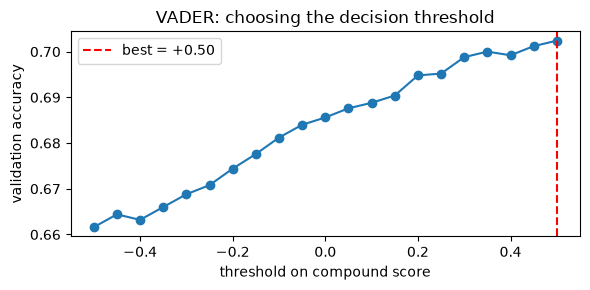

In [10]:
# Compound score of every validation review
val_compound = np.array([vader.polarity_scores(t)["compound"] for t in val["text"]])

thresholds = np.round(np.arange(-0.5, 0.51, 0.05), 2)   # -0.50, -0.45, ..., 0.50
val_accuracies = [((val_compound >= th).astype(int) == val["label"].values).mean()
                  for th in thresholds]

best_threshold = float(thresholds[int(np.argmax(val_accuracies))])
print(f"Best threshold on validation: {best_threshold:+.2f} "
      f"(accuracy {max(val_accuracies):.1%})")

plt.figure(figsize=(6, 3))
plt.plot(thresholds, val_accuracies, marker="o")
plt.axvline(best_threshold, color="red", linestyle="--", label=f"best = {best_threshold:+.2f}")
plt.xlabel("threshold on compound score")
plt.ylabel("validation accuracy")
plt.title("VADER: choosing the decision threshold")
plt.legend()
plt.tight_layout()
plt.show()

### B.2 Final evaluation on the test set

In [11]:
with Timer() as t:
    test_compound = np.array([vader.polarity_scores(s)["compound"] for s in test["text"]])
    test_pred_vader = (test_compound >= best_threshold).astype(int)

metrics_vader = evaluate(test["label"], test_pred_vader)
print_report("VADER (test set)", metrics_vader)
print(f"\nPrediction time for {len(test):,} reviews: {t.seconds:.3f} s")

save_results(
    "heuristic_vader", metrics_vader,
    family="heuristic",
    n_train_examples=0,
    train_seconds=0.0,
    predict_seconds=t.seconds,
    threshold=best_threshold,
)
save_predictions("heuristic_vader", test["text"], test["label"], test_pred_vader);

=== VADER (test set) ===
accuracy        : 0.7106
precision_macro : 0.7192
recall_macro    : 0.7106
f1_macro        : 0.7077
confusion matrix (rows = true, columns = predicted):
               pred_neg  pred_pos
  true_neg         1529       971
  true_pos          476      2024

Prediction time for 5,000 reviews: 5.294 s
Results saved to results\heuristic_vader.json


### B.3 Where does VADER fail?
Looking at errors is one of the most useful habits in NLP: it tells you *why* a model fails, not only *how often*.

In [12]:
errors = test.assign(compound=test_compound, pred=test_pred_vader)
errors = errors[errors["pred"] != errors["label"]]

print("Predicted POSITIVE, but actually NEGATIVE (highest compound first):")
for _, row in errors[errors["label"] == 0].nlargest(5, "compound").iterrows():
    print(f"  {row['compound']:+.2f}  {row['text'][:250]} [...]\n")

print("\nPredicted NEGATIVE, but actually POSITIVE (lowest compound first):")
for _, row in errors[errors["label"] == 1].nsmallest(5, "compound").iterrows():
    print(f"  {row['compound']:+.2f}  {row['text'][:250]} [...]\n")

Predicted POSITIVE, but actually NEGATIVE (highest compound first):
  +1.00  I have to say that I had low expectations for the movie before viewing it. All the people around said it was great, but I perfectly knew what they like. They like Aerosmith's song which is indeed great, they like the amazing special effects which had [...]

  +1.00  This was Hitchcock's third Hollywood feature, and it appears he was yet to settle into a pattern of consistency, turning from faithful adaptation of classic novel in Rebecca, to espionage thriller in Foreign Correspondent, and now this romantic comed [...]

  +1.00  The Time Machine starts in New York during 1899 where Professor Alexander Hartdegen (Guy Pearce) proposes to his beloved girlfriend Emma (Sienna Guillory) who accepts, unfortunately just after they are attacked by a mugger & Emma is shot dead & dies  [...]

  +1.00  I read the book after seeing the movie and didn't care for it, finding it somewhat trashy; but trashy books often make goo

Typical failure patterns you will see:
- **Irony and sarcasm:** positive words used to mean the opposite.
- **Domain-specific meaning:** in a review, *"predictable"* or *"long"* is negative, but VADER is a general-purpose lexicon.
- **Mixed reviews**, which praise some aspects and criticise others; the many strong words cancel each other out.
- **Plot descriptions**: words like *"murder"*, *"evil"* or *"death"* describe the story, not the reviewer's opinion, but VADER counts them as negative.

## Summary: heuristics

| | |
|---|---|
| ✅ **Strengths** | No labelled data needed · fully transparent (every decision can be explained) · very fast · easy to fix a specific error by adding a rule |
| ❌ **Weaknesses** | Small, fixed vocabulary · no notion of which words matter most in *this* domain · cannot learn domain-specific words · rules become complex and fragile as they grow |
| 💡 **When to use** | As a **first baseline** when you have no data, for very narrow domains, or to create *weak labels* for training a model later |

**Next:** `03_machine_learning_approach.ipynb`, where we let the computer learn the word weights from the 22,500 labelled training reviews.